# UNSW Dataset


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.preprocessing import  MinMaxScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.feature_selection import mutual_info_classif
import seaborn as sns

#from sklearn.model_selection import train_test_split
plt.style.use("seaborn-v0_8-whitegrid")


## Initial Exploratory Data Analysis (EDA) of the UNSW-NB15 Dataset

In [3]:
df_train = pd.read_csv('data/UNSW_NB15_training-set.csv')
df_test = pd.read_csv('data/UNSW_NB15_testing-set.csv')


# 1. Dataset shape
print(f"Training Dataset Shape: {df_train.shape}")
print(f" Testing Dataset Shape: {df_test.shape}")
# 2. Data types of each feature
print("\nData Types in Training:")
print(df_train.dtypes)
print("\nData Types in Testing:")
print(df_test.dtypes)

#Dropping id column since it will make all data unique
df_train = df_train.drop(columns=['id'], errors='ignore')
df_test = df_test.drop(columns=['id'], errors='ignore')

# 3. Number and percentage of missing values per column in training
missing_count = df_train.isnull().sum()
missing_pct = (df_train.isnull().sum() / len(df_train)) * 100
missing_df = pd.concat([missing_count, missing_pct], axis=1, keys=['Count', 'Percentage (%)'])
print("\nMissing Values in Training:")
print(missing_df)

# 4. Number and percentage of missing values per column in testing
missing_count = df_test.isnull().sum()
missing_pct = (df_test.isnull().sum() / len(df_test)) * 100
missing_df = pd.concat([missing_count, missing_pct], axis=1, keys=['Count', 'Percentage (%)'])
print("\nMissing Values in Testinhg:")
print(missing_df)

# 5. Counting the missing values in categorical data


missing_indicators = ["-", "None", "none", " ", "null"]

# 5.1 Check the entire dataframe for any of these values
is_missing_train = df_train.isin(missing_indicators)
is_missing_test = df_test.isin(missing_indicators)

# 5.2 Get the counts per column Training
ghost_counts_train = is_missing_train.sum()
ghost_report_train = ghost_counts_train[ghost_counts_train > 0]

# 5.3 Calculate Percentage Training
total_rows = len(df_train)
ghost_percentage_train = (ghost_report_train / total_rows) * 100

print("Columns with 'Ghost' Missing Values (Count and %) in Training:")
for col in ghost_report_train.index:
    print(f"{col}: {ghost_report_train[col]} rows ({ghost_percentage_train[col]:.2f}%)")


# 5.4 Get the counts per column Testing
ghost_counts_test = is_missing_test.sum()
ghost_report_test = ghost_counts_test[ghost_counts_test > 0]

# 5.5 Calculate Percentage Testing
total_rows = len(df_test)
ghost_percentage_test = (ghost_report_test / total_rows) * 100

print("Columns with 'Ghost' Missing Values (Count and %) in Testing:")
for col in ghost_report_test.index:
    print(f"{col}: {ghost_report_test[col]} rows ({ghost_percentage_test[col]:.2f}%)")



# 6. Number of duplicate rows in Training
print(f"\nNumber of Duplicate Rows in Training: {df_train.duplicated().sum()}")

# 7. Number of duplicate rows in Testing
print(f"\nNumber of Duplicate Rows in Testing: {df_test.duplicated().sum()}")

# 8. Class distribution of the label column (Normal vs Attack) in training
# 'label' is  0 for Normal and 1 for Attack
print("\nClass Distribution in Training:")
print(df_train['label'].value_counts())
print(df_train['label'].value_counts(normalize=True) * 100) # For percentages


# 9. Class distribution of the label column (Normal vs Attack) in testing
# 'label' is  0 for Normal and 1 for Attack
print("\nClass Distribution in Testing:")
print(df_test['label'].value_counts())
print(df_test['label'].value_counts(normalize=True) * 100) # For percentages


# 10. Statistical summary of numerical features in Training
print("\nStatistical Summary in Training:")
display(df_train.describe())

# 11. Statistical summary of numerical features in Testing
print("\nStatistical Summary in Testing:")
display(df_test.describe())

# 12. Count of unique values for each categorical feature in training

print("\nUnique Values in Categorical Features in Training:")
CAT_COLS = ["proto", "service", "state", "attack_cat"]
for col in CAT_COLS:
    if col in df_train.columns:
        df_train[col] = df_train[col].astype(str).str.strip()
        print(f"{col}: {df_train[col].nunique()} unique values")



#13. Count of unique values for each categorical feature in testing

print("\nUnique Values in Categorical Features in Testing:")
CAT_COLS = ["proto", "service", "state", "attack_cat"]
for col in CAT_COLS:
    if col in df_test.columns:
        df_test[col] = df_test[col].astype(str).str.strip()
        print(f"{col}: {df_test[col].nunique()} unique values")



print(f"Training Dataset Shape: {df_train.shape}")
print(f" Testing Dataset Shape: {df_test.shape}")

Training Dataset Shape: (175341, 45)
 Testing Dataset Shape: (82332, 45)

Data Types in Training:
id                     int64
dur                  float64
proto                    str
service                  str
state                    str
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_

,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,175341.000000,175341.000000,175341.000000,1.753410e+05,1.753410e+05,1.753410e+05,175341.000000,175341.000000,1.753410e+05,1.753410e+05,...,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000
mean,1.359389,20.298664,18.969591,8.844844e+03,1.492892e+04,9.540619e+04,179.546997,79.609567,7.345403e+07,6.712056e+05,...,5.383538,4.206255,8.729881,0.014948,0.014948,0.133066,6.955789,9.100758,0.015752,0.680622
std,6.480249,136.887597,110.258271,1.747656e+05,1.436542e+05,1.654010e+05,102.940011,110.506863,1.883574e+08,2.421312e+06,...,8.047104,5.783585,10.956186,0.126048,0.126048,0.701208,8.321493,10.756952,0.124516,0.466237
min,0.000000,1.000000,0.000000,2.800000e+01,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,3.278614e+01,62.000000,0.000000,1.305334e+04,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000
50%,0.001582,2.000000,2.000000,4.300000e+02,1.640000e+02,3.225807e+03,254.000000,29.000000,8.796748e+05,1.447023e+03,...,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,3.000000,4.000000,0.000000,1.000000
75%,0.668069,12.000000,10.000000,1.418000e+03,1.102000e+03,1.250000e+05,254.000000,252.000000,8.888889e+07,2.784487e+04,...,5.000000,3.000000,12.000000,0.000000,0.000000,0.000000,9.000000,12.000000,0.000000,1.000000
max,59.999989,9616.000000,10974.000000,1.296523e+07,1.465555e+07,1.000000e+06,255.000000,254.000000,5.988000e+09,2.242273e+07,...,51.000000,46.000000,65.000000,4.000000,4.000000,30.000000,60.000000,62.000000,1.000000,1.000000



Statistical Summary in Testing:


,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,82332.000000,82332.000000,82332.000000,8.233200e+04,8.233200e+04,8.233200e+04,82332.000000,82332.000000,8.233200e+04,8.233200e+04,...,82332.000000,82332.000000,82332.000000,82332.000000,82332.000000,82332.000000,82332.000000,82332.000000,82332.000000,82332.000000
mean,1.006756,18.666472,17.545936,7.993908e+03,1.323379e+04,8.241089e+04,180.967667,95.713003,6.454902e+07,6.305470e+05,...,4.928898,3.663011,7.456360,0.008284,0.008381,0.129743,6.468360,9.164262,0.011126,0.550600
std,4.710444,133.916353,115.574086,1.716423e+05,1.514715e+05,1.486204e+05,101.513358,116.667722,1.798618e+08,2.393001e+06,...,8.389545,5.915386,11.415191,0.091171,0.092485,0.638683,8.543927,11.121413,0.104891,0.497436
min,0.000000,1.000000,0.000000,2.400000e+01,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,2.860611e+01,62.000000,0.000000,1.120247e+04,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,2.000000,0.000000,0.000000
50%,0.014138,6.000000,2.000000,5.340000e+02,1.780000e+02,2.650177e+03,254.000000,29.000000,5.770032e+05,2.112951e+03,...,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,3.000000,5.000000,0.000000,1.000000
75%,0.719360,12.000000,10.000000,1.280000e+03,9.560000e+02,1.111111e+05,254.000000,252.000000,6.514286e+07,1.585808e+04,...,4.000000,3.000000,6.000000,0.000000,0.000000,0.000000,7.000000,11.000000,0.000000,1.000000
max,59.999989,10646.000000,11018.000000,1.435577e+07,1.465753e+07,1.000000e+06,255.000000,253.000000,5.268000e+09,2.082111e+07,...,59.000000,38.000000,63.000000,2.000000,2.000000,16.000000,60.000000,62.000000,1.000000,1.000000



Unique Values in Categorical Features in Training:
proto: 133 unique values
service: 13 unique values
state: 9 unique values
attack_cat: 10 unique values

Unique Values in Categorical Features in Testing:
proto: 131 unique values
service: 13 unique values
state: 7 unique values
attack_cat: 10 unique values
Training Dataset Shape: (175341, 44)
 Testing Dataset Shape: (82332, 44)


## EXTRA Just checking those unique 133 values in proto and which of them is mapped to a null value in service

In [4]:
# 1. Define the missing indicators again (just to be sure)
missing_indicators = ["-", "None", "none", " ", "null"]

# 2. Identify rows that contain ANY ghost missing value
# We use .any(axis=1) to find rows where at least one column has a ghost value
rows_with_ghosts = df_train[df_train.isin(missing_indicators).any(axis=1)]

# 3. Get the unique protocols associated with these "ghost" rows
protocols_with_nulls = rows_with_ghosts['proto'].unique()

print(f"Number of protocols associated with missing values: {len(protocols_with_nulls)}")


Number of protocols associated with missing values: 133


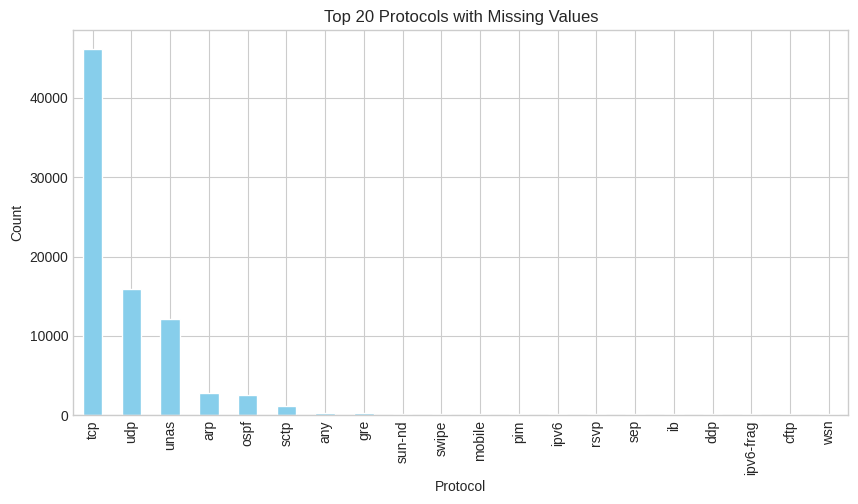

In [5]:
import matplotlib.pyplot as plt
# Plotting the top 20 protocols with ghosts
rows_with_ghosts['proto'].value_counts().head(20).plot(kind='bar', color='skyblue', figsize=(10,5))
plt.title("Top 20 Protocols with Missing Values")
plt.ylabel("Count")
plt.xlabel("Protocol")
plt.show()

Checking some of the protocols with null values if they are mapped to attacks

In [6]:
#EXTRA Just checking those unique 133 values in proto
# Check ARP mapping
print("--- ARP Attack Mapping ---")
arp_mapping = df_train[df_train['proto'] == 'arp']['attack_cat'].value_counts()
print(arp_mapping)

# Check OSPF mapping
print("\n--- OSPF Attack Mapping ---")
ospf_mapping = df_train[df_train['proto'] == 'ospf']['attack_cat'].value_counts()
print(ospf_mapping)


--- ARP Attack Mapping ---
attack_cat
Normal    2859
Name: count, dtype: int64

--- OSPF Attack Mapping ---
attack_cat
Exploits          1238
DoS                726
Reconnaissance     182
Fuzzers            141
Backdoor           139
Analysis            67
Normal              64
Generic             38
Name: count, dtype: int64


## Preprocessing

### Removing duplicates

In [7]:
print(f"Duplicate Rows(Train): {df_train.duplicated().sum()}")
print(f"Duplicate Rows(Test): {df_test.duplicated().sum()}")


df_train = df_train.drop_duplicates()
df_test = df_test.drop_duplicates()

# Verifying

print("--- After Removing Duplicates ---")
print(f"New Training Dataset Shape: {df_train.shape}")
print(f"New Testing Dataset Shape: {df_test.shape}")



Duplicate Rows(Train): 67601
Duplicate Rows(Test): 26387
--- After Removing Duplicates ---
New Training Dataset Shape: (107740, 44)
New Testing Dataset Shape: (55945, 44)


## Removing the label and attack_cat and encoding attack_cat using label encoding

In [8]:
X_train = df_train.drop(columns=['label', 'attack_cat'], errors='ignore')
X_test = df_test.drop(columns=['label', 'attack_cat'], errors='ignore')

le_target = LabelEncoder()

#Encode the  'attack_cat' column
y_train = le_target.fit_transform(df_train['attack_cat'].str.strip())
y_test = le_target.transform(df_test['attack_cat'].str.strip())

# Create a dictionary to see which number belongs to which attack
mapping = dict(zip(le_target.classes_, le_target.transform(le_target.classes_)))

print("Attack Category to Number Mapping:")
for name, num in mapping.items():
    print(f"{num} : {name}")

print(f"After removing label, attack_cat in Training: {X_train.shape}")
print(f"After removing label, attack_cat in Testing: {X_test.shape}")

Attack Category to Number Mapping:
0 : Analysis
1 : Backdoor
2 : DoS
3 : Exploits
4 : Fuzzers
5 : Generic
6 : Normal
7 : Reconnaissance
8 : Shellcode
9 : Worms
After removing label, attack_cat in Training: (107740, 42)
After removing label, attack_cat in Testing: (55945, 42)


### Encoding the Categorical Features using One-hot Encoding

In [9]:
#  Count of unique values for each categorical feature in training after removing the duplicates and the missing values

print("\nUnique Values in Categorical Features in Training:")
CAT_COLS = ["proto", "service", "state"]
for col in CAT_COLS:
    if col in X_train.columns:
        X_train[col] = X_train[col].astype(str).str.strip()
        print(f"{col}: {X_train[col].nunique()} unique values")



# Count of unique values for each categorical feature in testing after removing the duplicates and the missing values

print("\nUnique Values in Categorical Features in Testing:")
CAT_COLS = ["proto", "service", "state"]
for col in CAT_COLS:
    if col in X_test.columns:
        X_test[col] = X_test[col].astype(str).str.strip()
        print(f"{col}: {X_test[col].nunique()} unique values")



#Encoding using One Hot Encoding for the 3 categorical columns
CAT_OHE = ["proto", "state", "service"]

def build_encoder_only(X_train: pd.DataFrame):
    preprocessor = ColumnTransformer(
        transformers=[

            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_OHE),
        ],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )
    return preprocessor

#  Initialize and fit the encoder

encoder = build_encoder_only(X_train)

#  Run the transformation
X_train_encoded = pd.DataFrame(
    encoder.fit_transform(X_train),
    columns=encoder.get_feature_names_out(),
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    encoder.transform(X_test),
    columns=encoder.get_feature_names_out(),
    index=X_test.index
)

X_train = X_train_encoded
X_test = X_test_encoded


print(f"\nFinal feature count in Training: {X_train_encoded.shape[1]}")
print(f"Final feature count in Testing: {X_test_encoded.shape[1]}")


Unique Values in Categorical Features in Training:
proto: 133 unique values
service: 13 unique values
state: 9 unique values

Unique Values in Categorical Features in Testing:
proto: 131 unique values
service: 13 unique values
state: 7 unique values

Final feature count in Training: 194
Final feature count in Testing: 194


In [10]:
print("--- Final Check ---")
print(f"Training Features (X): {X_train.shape}")
print(f"Training Target (y): {y_train.shape}")

print(f"Training Features (X): {X_test.shape}")
print(f"Training Target (y): {y_test.shape}")


--- Final Check ---
Training Features (X): (107740, 194)
Training Target (y): (107740,)
Training Features (X): (55945, 194)
Training Target (y): (55945,)


### Normalization by using MinMaxScaler

In [42]:
scaler = MinMaxScaler()

#Fit on Training
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Verify the range
print(f"Max value in training: {X_train_scaled.max().max()}")
print(f"Min value in training: {X_train_scaled.min().min()}")


# Verify the range
print(f"Max value in testing: {X_test_scaled.max().max()}")
print(f"Min value in testing: {X_test_scaled.min().min()}")



Max value in training: 1.0000000000000002
Min value in training: 0.0
Max value in testing: 1.9257076805331639
Min value in testing: -0.0027100271002710036


## Feature Selection: Mutual Information (MI)

Top 20 Features by Mutual Information:
sbytes            0.882789
dbytes            0.675181
smean             0.615821
dmean             0.541413
sttl              0.518508
sload             0.481263
ct_state_ttl      0.463557
dttl              0.460061
dload             0.424442
dpkts             0.423762
dinpkt            0.417981
rate              0.415865
dur               0.383942
synack            0.375069
tcprtt            0.374091
ackdat            0.361330
sinpkt            0.314674
dloss             0.314178
djit              0.298175
sjit              0.296085
spkts             0.293166
ct_srv_dst        0.279818
sloss             0.255258
ct_srv_src        0.237516
ct_dst_src_ltm    0.214066
dtype: float64


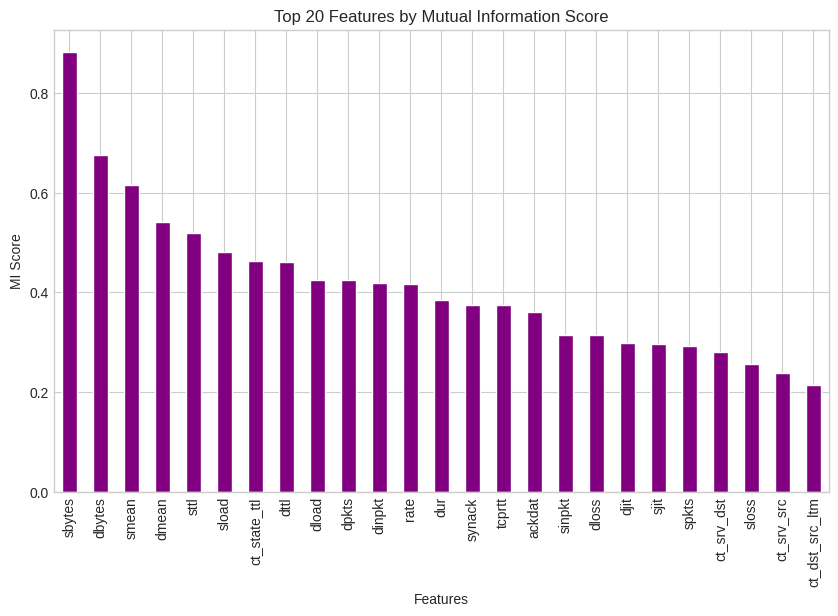

In [12]:
#MI ranks features
mi_scores_values = mutual_info_classif(X_train_scaled, y_train, random_state=42)
mi_scores = pd.Series(mi_scores_values, index=X_train_scaled.columns).sort_values(ascending=False)

#Report: top 25 features by MI score
print("Top 20 Features by Mutual Information:")
print(mi_scores.head(25))


import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
mi_scores.head(25).plot(kind='bar', color='purple')
plt.title("Top 20 Features by Mutual Information Score")
plt.ylabel("MI Score")
plt.xlabel("Features")
plt.show()

### Note on Mutual Information:
Captures Non-Linear Relationships: Network attacks are rarely "straight-line" logic. MI can detect complex patterns where an attack is hidden within a specific range of values. So i'll choose this method as a feature selection.

In [13]:
#Apply Pearson on MI top 50 features
top_50_features = mi_scores.head(50).index.tolist()

#a dataframe of just these candidates
df_candidates = X_train[top_50_features]

#Correlation Matrix
corr_matrix = df_candidates.corr().abs()

#Identify redundant pairs (Correlation > 0.90)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > 0.90)]

final_pool = top_50_features.copy()
to_drop = set()

# 2. Re-examine the redundant pairs
for col in upper.columns:
    # Find features highly correlated with 'col'
    high_corr_features = upper.index[upper[col] > 0.90].tolist()

    for feature in high_corr_features:
        # We have a redundant pair: (feature, col)
        # Get their MI scores from your mi_scores Series
        score_feature = mi_scores[feature]
        score_col = mi_scores[col]

        # Identify the weaker one
        if score_feature < score_col:
            weaker_feature = feature
        else:
            weaker_feature = col

        to_drop.add(weaker_feature)

# 3. Clean the final pool
final_pool = [f for f in final_pool if f not in to_drop]

print(f"Redundant Features Dropped (Lower MI): {to_drop}")
print(f"Remaining High-Signal Features: {len(final_pool)}")
print(f"Final Selection: {final_pool}")


Redundant Features Dropped (Lower MI): {'tcprtt', 'dpkts', 'state_FIN', 'spkts', 'dloss', 'ct_srv_src', 'sloss', 'proto_tcp', 'ackdat', 'dwin'}
Remaining High-Signal Features: 40
Final Selection: ['sbytes', 'dbytes', 'smean', 'dmean', 'sttl', 'sload', 'ct_state_ttl', 'dttl', 'dload', 'dinpkt', 'rate', 'dur', 'synack', 'sinpkt', 'djit', 'sjit', 'ct_srv_dst', 'ct_dst_src_ltm', 'ct_dst_ltm', 'ct_src_ltm', 'ct_dst_sport_ltm', 'state_INT', 'service_-', 'ct_src_dport_ltm', 'response_body_len', 'service_dns', 'stcpb', 'swin', 'dtcpb', 'proto_udp', 'state_CON', 'service_http', 'ct_flw_http_mthd', 'trans_depth', 'proto_unas', 'service_smtp', 'service_pop3', 'service_ssh', 'service_ftp-data', 'proto_ospf']


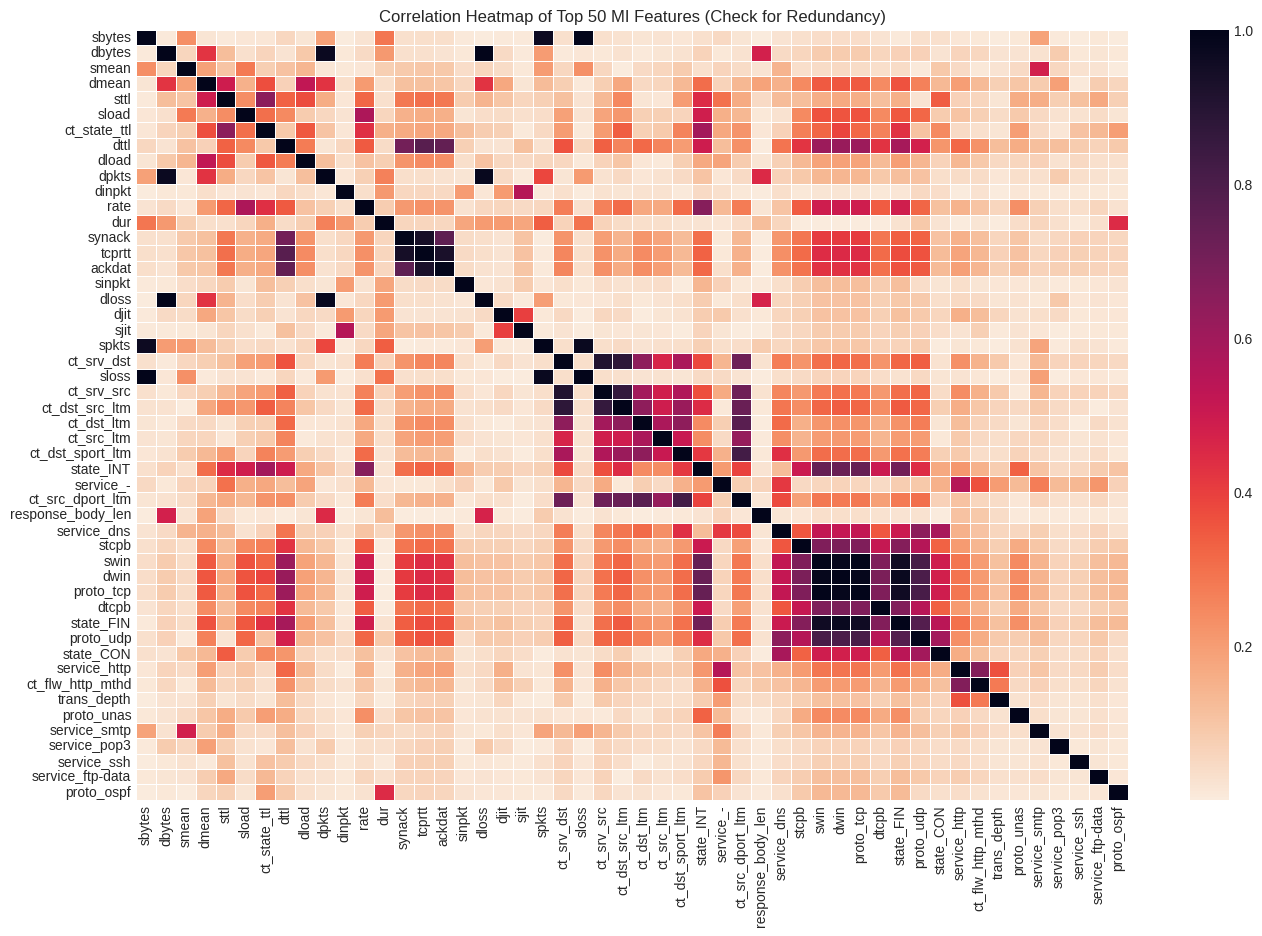

In [14]:
plt.figure(figsize=(16, 10))
sns.heatmap(corr_matrix, annot=False, cmap='rocket_r', linewidths=0.5)
plt.title("Correlation Heatmap of Top 50 MI Features (Check for Redundancy)")
plt.show()

In [15]:
# Filter the dataframes
X_train_final = X_train[final_pool]
X_test_final = X_test[final_pool]

print(f"Final training shape: {X_train_final.shape}")
print(f"Final testing shape: {X_test_final.shape}")


Final training shape: (107740, 40)
Final testing shape: (55945, 40)


In [16]:
# (Just in case the 'to_drop' logic shuffled anything)
final_ranked_features = mi_scores[final_pool].sort_values(ascending=False)

# 2. Slice the top 30
top_30_final = final_ranked_features.head(30)

# 3. Display the results
print("\n" + "="*30)
print("FINAL TOP 30 FEATURES (Redundancy-Free)")
print("="*30)
for i, (feature, score) in enumerate(top_30_final.items(), 1):
    print(f"{i}. {feature:<25} (MI Score: {score:.4f})")

# 4. Save the names to a list for your model training
final_feature_list = top_30_final.index.tolist()


FINAL TOP 30 FEATURES (Redundancy-Free)
1. sbytes                    (MI Score: 0.8828)
2. dbytes                    (MI Score: 0.6752)
3. smean                     (MI Score: 0.6158)
4. dmean                     (MI Score: 0.5414)
5. sttl                      (MI Score: 0.5185)
6. sload                     (MI Score: 0.4813)
7. ct_state_ttl              (MI Score: 0.4636)
8. dttl                      (MI Score: 0.4601)
9. dload                     (MI Score: 0.4244)
10. dinpkt                    (MI Score: 0.4180)
11. rate                      (MI Score: 0.4159)
12. dur                       (MI Score: 0.3839)
13. synack                    (MI Score: 0.3751)
14. sinpkt                    (MI Score: 0.3147)
15. djit                      (MI Score: 0.2982)
16. sjit                      (MI Score: 0.2961)
17. ct_srv_dst                (MI Score: 0.2798)
18. ct_dst_src_ltm            (MI Score: 0.2141)
19. ct_dst_ltm                (MI Score: 0.1956)
20. ct_src_ltm                (MI Sco

In [17]:
X_train_Filter = X_train_final[final_feature_list]
X_test_Filter = X_test_final[final_feature_list]

print(f"Final training shape: {X_train_Filter.shape}")
print(f"Final testing shape: {X_test_Filter.shape}")

Final training shape: (107740, 30)
Final testing shape: (55945, 30)


In [18]:
print(f"Top 10: {final_feature_list[:10]}")
print(f"\nTop 20: {final_feature_list[:20]}")
print(f"\nTop 30: {final_feature_list[:30]}")

Top 10: ['sbytes', 'dbytes', 'smean', 'dmean', 'sttl', 'sload', 'ct_state_ttl', 'dttl', 'dload', 'dinpkt']

Top 20: ['sbytes', 'dbytes', 'smean', 'dmean', 'sttl', 'sload', 'ct_state_ttl', 'dttl', 'dload', 'dinpkt', 'rate', 'dur', 'synack', 'sinpkt', 'djit', 'sjit', 'ct_srv_dst', 'ct_dst_src_ltm', 'ct_dst_ltm', 'ct_src_ltm']

Top 30: ['sbytes', 'dbytes', 'smean', 'dmean', 'sttl', 'sload', 'ct_state_ttl', 'dttl', 'dload', 'dinpkt', 'rate', 'dur', 'synack', 'sinpkt', 'djit', 'sjit', 'ct_srv_dst', 'ct_dst_src_ltm', 'ct_dst_ltm', 'ct_src_ltm', 'ct_dst_sport_ltm', 'state_INT', 'service_-', 'ct_src_dport_ltm', 'response_body_len', 'service_dns', 'stcpb', 'swin', 'dtcpb', 'proto_udp']


In [19]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
warnings.filterwarnings("ignore")

from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier


rf_engine = RandomForestClassifier(n_estimators=20, max_depth=8, n_jobs=-1, random_state=42)


selector = RFECV(
    estimator=rf_engine,
    step=5,
    cv=StratifiedKFold(3),
    scoring='f1_weighted',
    min_features_to_select=5,
    n_jobs=-1,
    verbose=1
)


print("Starting RFECV optimization...")
selector.fit(X_train, y_train)


optimal_feature_count = selector.n_features_
optimal_features_rfecv = X_train.columns[selector.support_].tolist()

print(f"\n--- RFECV Results ---")
print(f"Optimal number of features: {optimal_feature_count}")
print(f"Selected Subset: {optimal_features_rfecv}")




Starting RFECV optimization...
Fitting estimator with 194 features.
Fitting estimator with 194 features.
Fitting estimator with 194 features.
Fitting estimator with 144 features.
Fitting estimator with 144 features.
Fitting estimator with 144 features.
Fitting estimator with 94 features.
Fitting estimator with 94 features.
Fitting estimator with 94 features.
Fitting estimator with 44 features.
Fitting estimator with 44 features.
Fitting estimator with 44 features.
Fitting estimator with 194 features.
Fitting estimator with 144 features.
Fitting estimator with 94 features.

--- RFECV Results ---
Optimal number of features: 44
Selected Subset: ['proto_tcp', 'proto_udp', 'state_CON', 'state_FIN', 'state_INT', 'service_-', 'service_dns', 'service_ftp-data', 'service_http', 'service_smtp', 'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'dtcpb', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean'

In [21]:
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
warnings.filterwarnings("ignore")

from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.ensemble import RandomForestClassifier



clf = RandomForestClassifier(
    n_estimators=10,
    max_depth=5,
    min_samples_leaf=10,
    n_jobs=-1,
    random_state=42
)

# 2. Initialize SFS
sfs = SequentialFeatureSelector(
    estimator=clf,
    n_features_to_select=15,
    direction='forward',
    scoring='f1_weighted',
    cv=3,
    n_jobs=-1
)


sfs.fit(X_train, y_train)

X_train_sfs = sfs.transform(X_train)
X_test_sfs  = sfs.transform(X_test)

sfs_features = X_train.columns[sfs.get_support()].tolist()

print(f"SFS Selected {len(sfs_features)} Features: {sfs_features}")

SFS Selected 15 Features: ['proto_arp', 'proto_igmp', 'proto_ippc', 'proto_ipv6-no', 'state_FIN', 'state_INT', 'service_-', 'service_smtp', 'sbytes', 'sttl', 'dinpkt', 'swin', 'smean', 'ct_state_ttl', 'ct_dst_src_ltm']


## Random Forest Training

In [22]:
all_classes = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
CLASS_NAMES = ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']
RF_RESULTS = {}
SVM_RESULTS = {}
XGB_RESULTS = {}

In [23]:
from sklearn.metrics import accuracy_score

from sklearn.metrics import f1_score

from sklearn.metrics import classification_report

from sklearn.metrics import confusion_matrix


def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average='weighted')
    f1_mac = f1_score(y_true, y_pred, average='macro')
    print(f'\n=== {name} ===')
    print(f'Accuracy : {acc:.4f}   Weighted F1 : {f1:.4f}, Macro F1: {f1_mac:.4f}')
    print(classification_report(y_true, y_pred,
                                labels=all_classes,
                                target_names=CLASS_NAMES))
    cm = confusion_matrix(y_true, y_pred, labels=all_classes)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f'{name} — Confusion Matrix')
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    plt.tight_layout(); plt.show()
    return acc, f1, f1_mac



In [24]:
def _make_rf():
    return RandomForestClassifier(
        n_estimators=100, max_depth=15, min_samples_split=10,
        class_weight='balanced', n_jobs=-1, random_state=42)

## Random Forest Training


>>> Training Random Forest on: Full Dataset (K=194)

=== Full Dataset ===
Accuracy : 0.6352   Weighted F1 : 0.6967, Macro F1: 0.4684
                precision    recall  f1-score   support

      Analysis       0.05      0.28      0.08       446
      Backdoor       0.11      0.56      0.19       346
           DoS       0.45      0.30      0.36      1718
      Exploits       0.80      0.71      0.76      7609
       Fuzzers       0.24      0.75      0.37      4838
       Generic       1.00      0.83      0.91      3657
        Normal       1.00      0.59      0.74     34206
Reconnaissance       0.71      0.82      0.76      2703
     Shellcode       0.15      0.94      0.26       378
         Worms       0.16      0.77      0.27        44

      accuracy                           0.64     55945
     macro avg       0.47      0.66      0.47     55945
  weighted avg       0.86      0.64      0.70     55945



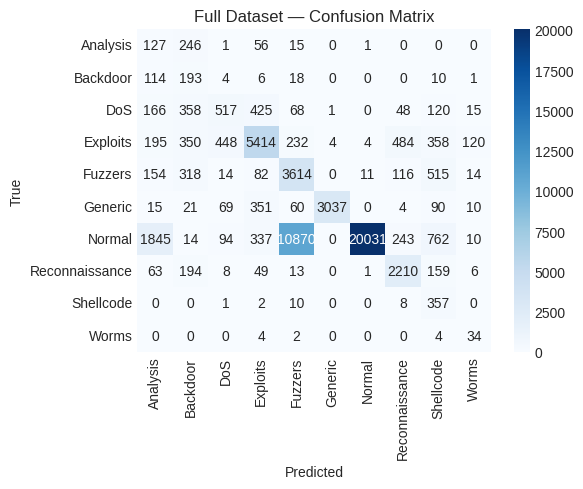


>>> Training Random Forest on: Filter (MI Top 30) (K=30)

=== Filter (MI Top 30) ===
Accuracy : 0.6426   Weighted F1 : 0.7025, Macro F1: 0.5242
                precision    recall  f1-score   support

      Analysis       0.05      0.33      0.09       446
      Backdoor       0.12      0.58      0.20       346
           DoS       0.46      0.33      0.39      1718
      Exploits       0.77      0.75      0.76      7609
       Fuzzers       0.23      0.72      0.35      4838
       Generic       0.98      0.86      0.92      3657
        Normal       1.00      0.59      0.74     34206
Reconnaissance       0.82      0.83      0.83      2703
     Shellcode       0.18      0.95      0.30       378
         Worms       0.57      0.82      0.67        44

      accuracy                           0.64     55945
     macro avg       0.52      0.68      0.52     55945
  weighted avg       0.86      0.64      0.70     55945



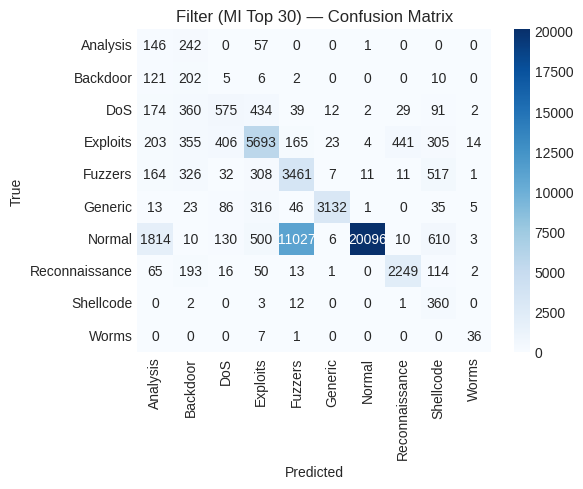


>>> Training Random Forest on: Wrapper 1 (RFECV) (K=44)

=== Wrapper 1 (RFECV) ===
Accuracy : 0.6429   Weighted F1 : 0.7024, Macro F1: 0.5037
                precision    recall  f1-score   support

      Analysis       0.05      0.28      0.08       446
      Backdoor       0.11      0.51      0.19       346
           DoS       0.45      0.32      0.37      1718
      Exploits       0.79      0.75      0.77      7609
       Fuzzers       0.24      0.73      0.36      4838
       Generic       0.98      0.86      0.92      3657
        Normal       1.00      0.59      0.74     34206
Reconnaissance       0.81      0.83      0.82      2703
     Shellcode       0.16      0.95      0.28       378
         Worms       0.40      0.73      0.51        44

      accuracy                           0.64     55945
     macro avg       0.50      0.66      0.50     55945
  weighted avg       0.86      0.64      0.70     55945



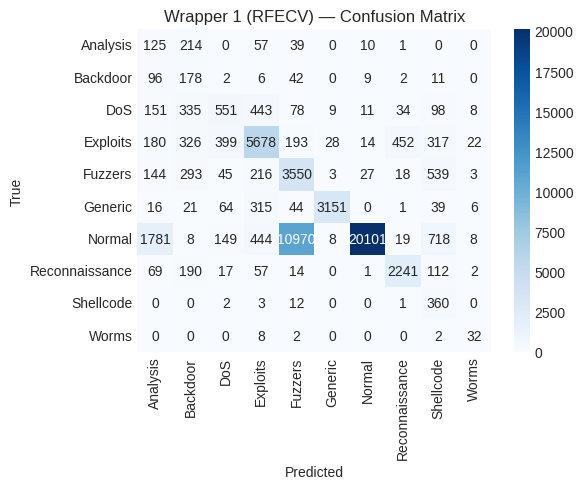


>>> Training Random Forest on: Wrapper 2 (SFS) (K=15)

=== Wrapper 2 (SFS) ===
Accuracy : 0.6311   Weighted F1 : 0.6923, Macro F1: 0.5122
                precision    recall  f1-score   support

      Analysis       0.08      0.53      0.13       446
      Backdoor       0.11      0.39      0.18       346
           DoS       0.30      0.29      0.30      1718
      Exploits       0.75      0.68      0.72      7609
       Fuzzers       0.22      0.68      0.33      4838
       Generic       0.97      0.88      0.92      3657
        Normal       1.00      0.59      0.74     34206
Reconnaissance       0.81      0.83      0.82      2703
     Shellcode       0.19      0.94      0.31       378
         Worms       0.54      0.89      0.67        44

      accuracy                           0.63     55945
     macro avg       0.50      0.67      0.51     55945
  weighted avg       0.85      0.63      0.69     55945



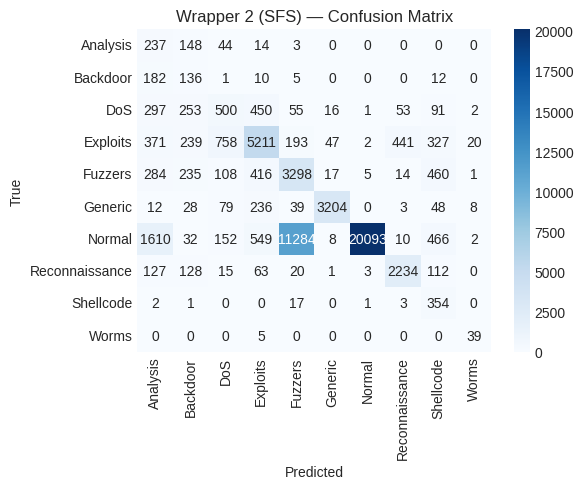


--- FINAL COMPARISON SUMMARY ---
                    Accuracy  Weighted F1  Macro F1      K
Full Dataset        0.635160     0.696700  0.468395  194.0
Filter (MI Top 30)  0.642595     0.702473  0.524212   30.0
Wrapper 1 (RFECV)   0.642899     0.702414  0.503698   44.0
Wrapper 2 (SFS)     0.631084     0.692321  0.512214   15.0


In [25]:

FEATURE_SUBSETS = {
    "Full Dataset": X_train.columns.tolist(),
    "Filter (MI Top 30)": final_feature_list,
    "Wrapper 1 (RFECV)": optimal_features_rfecv,
    "Wrapper 2 (SFS)": sfs_features
}

for name, f_list in FEATURE_SUBSETS.items():
    print(f"\n>>> Training Random Forest on: {name} (K={len(f_list)})")

    clf = _make_rf()


    clf.fit(X_train[f_list], y_train)
    y_pred = clf.predict(X_test[f_list])

    # Evaluate and store
    acc, f1, f1_mac = evaluate(name, y_test, y_pred)
    RF_RESULTS[name] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': f1_mac, 'K': len(f_list)}

# Final Comparison Table
import pandas as pd
summary_df = pd.DataFrame(RF_RESULTS).T
print("\n--- FINAL COMPARISON SUMMARY ---")
print(summary_df)


── SVM: Baseline (All Features) ──

=== SVM (Linear) - Baseline ===
Accuracy : 0.6197   Weighted F1 : 0.6562, Macro F1: 0.3342
                precision    recall  f1-score   support

      Analysis       0.16      0.53      0.25       446
      Backdoor       0.00      0.00      0.00       346
           DoS       0.55      0.02      0.03      1718
      Exploits       0.57      0.72      0.64      7609
       Fuzzers       0.22      0.80      0.35      4838
       Generic       0.96      0.81      0.88      3657
        Normal       0.97      0.61      0.75     34206
Reconnaissance       0.45      0.44      0.44      2703
     Shellcode       0.00      0.00      0.00       378
         Worms       0.00      0.00      0.00        44

      accuracy                           0.62     55945
     macro avg       0.39      0.39      0.33     55945
  weighted avg       0.79      0.62      0.66     55945



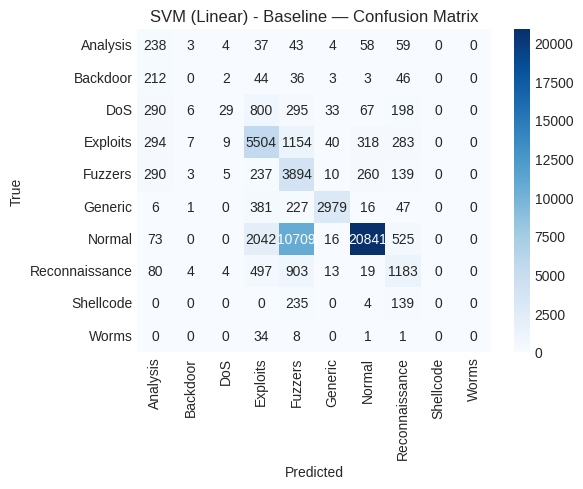


── SVM: Filter-based (MI) top-30 features ──

=== SVM (Linear) (MI, K=30) ===
Accuracy : 0.6210   Weighted F1 : 0.6563, Macro F1: 0.3315
                precision    recall  f1-score   support

      Analysis       0.17      0.56      0.26       446
      Backdoor       0.00      0.00      0.00       346
           DoS       0.82      0.01      0.01      1718
      Exploits       0.55      0.74      0.63      7609
       Fuzzers       0.22      0.75      0.34      4838
       Generic       0.95      0.81      0.88      3657
        Normal       0.97      0.62      0.75     34206
Reconnaissance       0.46      0.43      0.45      2703
     Shellcode       0.00      0.00      0.00       378
         Worms       0.00      0.00      0.00        44

      accuracy                           0.62     55945
     macro avg       0.41      0.39      0.33     55945
  weighted avg       0.80      0.62      0.66     55945



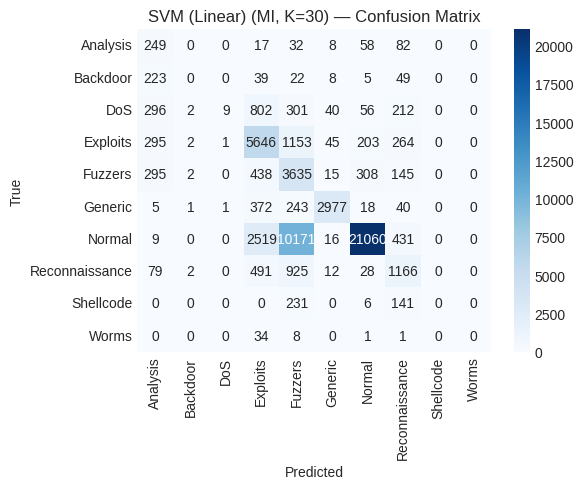


── SVM: Wrapper 1 (RFECV) top-25 features ──

=== SVM (Linear) (RFECV, K=25) ===
Accuracy : 0.6179   Weighted F1 : 0.6544, Macro F1: 0.3331
                precision    recall  f1-score   support

      Analysis       0.16      0.57      0.26       446
      Backdoor       0.00      0.00      0.00       346
           DoS       0.88      0.01      0.03      1718
      Exploits       0.57      0.74      0.64      7609
       Fuzzers       0.22      0.79      0.34      4838
       Generic       0.95      0.81      0.88      3657
        Normal       0.97      0.61      0.75     34206
Reconnaissance       0.44      0.44      0.44      2703
     Shellcode       0.00      0.00      0.00       378
         Worms       0.00      0.00      0.00        44

      accuracy                           0.62     55945
     macro avg       0.42      0.40      0.33     55945
  weighted avg       0.80      0.62      0.65     55945



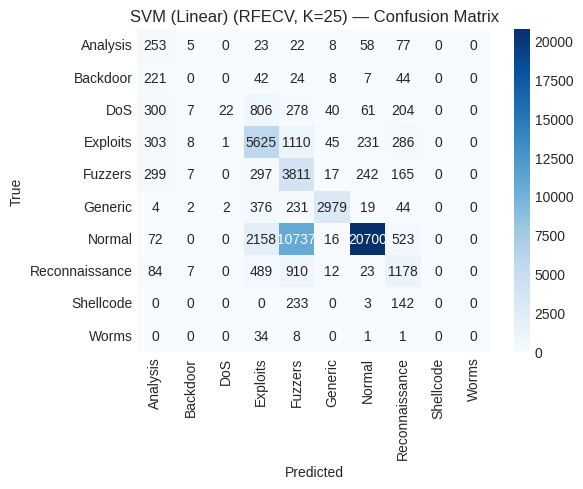


── SVM: Wrapper 2 (SFS) top-15 features ──

=== SVM (Linear) (SFS, K=15) ===
Accuracy : 0.5743   Weighted F1 : 0.6096, Macro F1: 0.2705
                precision    recall  f1-score   support

      Analysis       0.00      0.00      0.00       446
      Backdoor       0.00      0.00      0.00       346
           DoS       0.33      0.00      0.00      1718
      Exploits       0.49      0.61      0.54      7609
       Fuzzers       0.20      0.82      0.32      4838
       Generic       0.97      0.82      0.89      3657
        Normal       0.93      0.59      0.72     34206
Reconnaissance       0.28      0.21      0.24      2703
     Shellcode       0.00      0.00      0.00       378
         Worms       0.00      0.00      0.00        44

      accuracy                           0.57     55945
     macro avg       0.32      0.30      0.27     55945
  weighted avg       0.74      0.57      0.61     55945



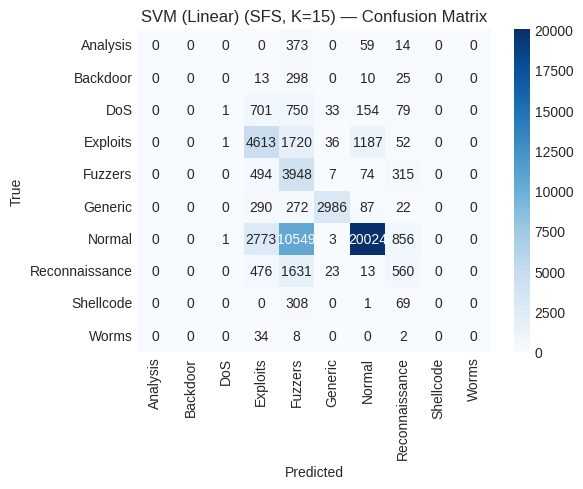


--- UNIFIED EVALUATION SUMMARY ---
                            Accuracy  Weighted F1  Macro F1      K
SVM (Linear) - Baseline     0.619680     0.656153  0.334223  194.0
SVM (Linear) (RFECV, K=25)  0.617893     0.654442  0.333095   44.0
SVM (Linear) (MI, K=30)     0.621003     0.656297  0.331544   30.0
SVM (Linear) (SFS, K=15)    0.574350     0.609586  0.270487   15.0


In [26]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
import pandas as pd

def _make_linear_svc():
    return Pipeline([
        ('clf', LinearSVC(C=1.0, max_iter=2000, random_state=42, dual='auto')),
    ])

#  Baseline Evaluation (K=194)
print(f'── SVM: Baseline (All Features) ──')
K_baseline = X_train.shape[1]
clf = _make_linear_svc()
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
label = 'SVM (Linear) - Baseline'
acc, f1, macro = evaluate(label, y_test, y_pred)

SVM_RESULTS[label] = {
    'Accuracy': acc,
    'Weighted F1': f1,
    'Macro F1': macro,
    'K': K_baseline
}

#  Filter-based Evaluation (K=30)
print(f'\n── SVM: Filter-based (MI) top-30 features ──')
K_mi = len(final_feature_list)
clf = _make_linear_svc()
clf.fit(X_train[final_feature_list], y_train)
y_pred = clf.predict(X_test[final_feature_list])
label = 'SVM (Linear) (MI, K=30)'
acc, f1, macro = evaluate(label, y_test, y_pred)

SVM_RESULTS[label] = {
    'Accuracy': acc,
    'Weighted F1': f1,
    'Macro F1': macro,
    'K': K_mi
}

# Wrapper 1: RFECV Evaluation 
print(f'\n── SVM: Wrapper 1 (RFECV) top-25 features ──')
K_rfecv = len(optimal_features_rfecv)
clf = _make_linear_svc()
clf.fit(X_train[optimal_features_rfecv], y_train)
y_pred = clf.predict(X_test[optimal_features_rfecv])
label = 'SVM (Linear) (RFECV, K=25)'
acc, f1, macro = evaluate(label, y_test, y_pred)

SVM_RESULTS[label] = {
    'Accuracy': acc,
    'Weighted F1': f1,
    'Macro F1': macro,
    'K': K_rfecv
}

# 5. Wrapper 2: SFS Evaluation (K=15)
print(f'\n── SVM: Wrapper 2 (SFS) top-15 features ──')
K_sfs = len(sfs_features)
clf = _make_linear_svc()
clf.fit(X_train[sfs_features], y_train)
y_pred = clf.predict(X_test[sfs_features])
label = 'SVM (Linear) (SFS, K=15)'
acc, f1, macro = evaluate(label, y_test, y_pred)

SVM_RESULTS[label] = {
    'Accuracy': acc,
    'Weighted F1': f1,
    'Macro F1': macro,
    'K': K_sfs
}

# Final Clean Summary Table
summary_df = pd.DataFrame(SVM_RESULTS).T
summary_df = summary_df.sort_values(by='Macro F1', ascending=False)
print("\n--- UNIFIED EVALUATION SUMMARY ---")
print(summary_df)

── Starting XGBoost Subset Evaluations ──

>>> Training: XGBoost - Baseline (K=194)

=== XGBoost - Baseline ===
Accuracy : 0.7470   Weighted F1 : 0.7704, Macro F1: 0.5191
                precision    recall  f1-score   support

      Analysis       0.09      0.16      0.12       446
      Backdoor       0.12      0.28      0.17       346
           DoS       0.63      0.10      0.17      1718
      Exploits       0.69      0.86      0.77      7609
       Fuzzers       0.30      0.70      0.42      4838
       Generic       0.99      0.84      0.91      3657
        Normal       0.96      0.76      0.85     34206
Reconnaissance       0.88      0.79      0.83      2703
     Shellcode       0.36      0.71      0.48       378
         Worms       0.70      0.36      0.48        44

      accuracy                           0.75     55945
     macro avg       0.57      0.56      0.52     55945
  weighted avg       0.84      0.75      0.77     55945



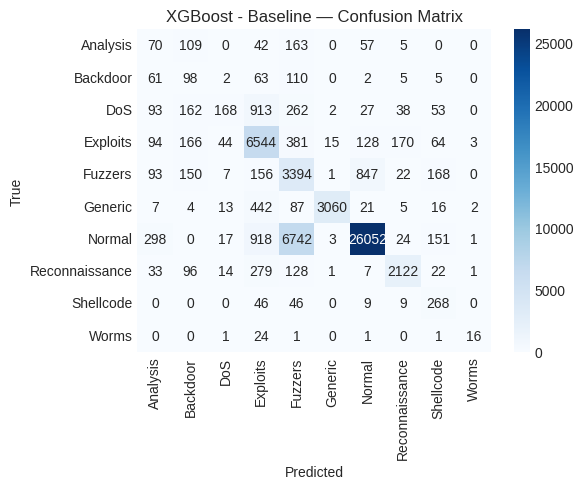


>>> Training: XGBoost (MI, K=30) (K=30)

=== XGBoost (MI, K=30) ===
Accuracy : 0.7468   Weighted F1 : 0.7707, Macro F1: 0.5258
                precision    recall  f1-score   support

      Analysis       0.11      0.15      0.13       446
      Backdoor       0.12      0.27      0.17       346
           DoS       0.59      0.09      0.16      1718
      Exploits       0.68      0.86      0.76      7609
       Fuzzers       0.30      0.71      0.42      4838
       Generic       0.99      0.83      0.90      3657
        Normal       0.97      0.76      0.85     34206
Reconnaissance       0.88      0.78      0.83      2703
     Shellcode       0.35      0.70      0.47       378
         Worms       0.64      0.52      0.57        44

      accuracy                           0.75     55945
     macro avg       0.56      0.57      0.53     55945
  weighted avg       0.84      0.75      0.77     55945



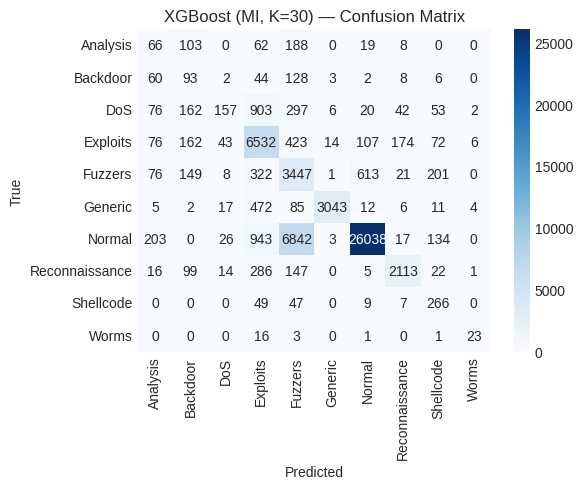


>>> Training: XGBoost (RFECV, K=25) (K=44)

=== XGBoost (RFECV, K=25) ===
Accuracy : 0.7470   Weighted F1 : 0.7706, Macro F1: 0.5372
                precision    recall  f1-score   support

      Analysis       0.12      0.20      0.15       446
      Backdoor       0.11      0.22      0.15       346
           DoS       0.59      0.11      0.18      1718
      Exploits       0.69      0.86      0.77      7609
       Fuzzers       0.30      0.72      0.43      4838
       Generic       0.99      0.84      0.91      3657
        Normal       0.96      0.76      0.85     34206
Reconnaissance       0.88      0.78      0.83      2703
     Shellcode       0.40      0.69      0.51       378
         Worms       0.67      0.55      0.60        44

      accuracy                           0.75     55945
     macro avg       0.57      0.57      0.54     55945
  weighted avg       0.84      0.75      0.77     55945



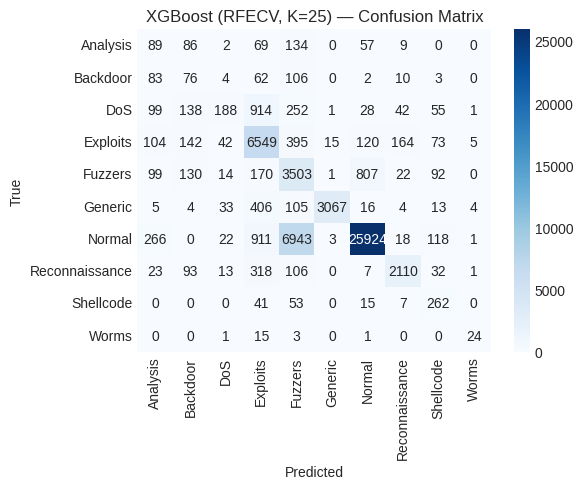


>>> Training: XGBoost (SFS, K=15) (K=15)

=== XGBoost (SFS, K=15) ===
Accuracy : 0.7255   Weighted F1 : 0.7505, Macro F1: 0.4940
                precision    recall  f1-score   support

      Analysis       0.02      0.00      0.00       446
      Backdoor       0.26      0.07      0.11       346
           DoS       0.56      0.07      0.12      1718
      Exploits       0.62      0.85      0.71      7609
       Fuzzers       0.26      0.72      0.38      4838
       Generic       0.99      0.83      0.90      3657
        Normal       0.98      0.73      0.84     34206
Reconnaissance       0.86      0.77      0.81      2703
     Shellcode       0.37      0.60      0.46       378
         Worms       0.59      0.61      0.60        44

      accuracy                           0.73     55945
     macro avg       0.55      0.53      0.49     55945
  weighted avg       0.84      0.73      0.75     55945



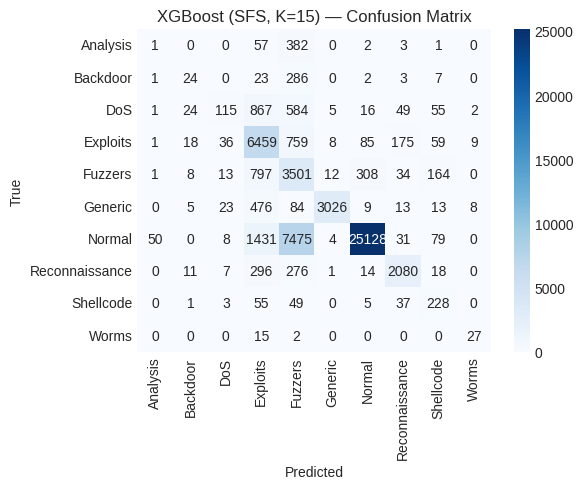


XGBOOST FEATURE SUBSET SUMMARY
                       Accuracy  Weighted F1  Macro F1      K
XGBoost (RFECV, K=25)  0.747019     0.770596  0.537168   44.0
XGBoost (MI, K=30)     0.746769     0.770721  0.525763   30.0
XGBoost - Baseline     0.747019     0.770392  0.519096  194.0
XGBoost (SFS, K=15)    0.725516     0.750466  0.494031   15.0


In [27]:
import xgboost as xgb
import pandas as pd

# 1. XGBoost Model Factory
def _make_xgb():
    return xgb.XGBClassifier(
        verbosity=0,
        random_state=42,
        eval_metric='mlogloss',
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method='hist',
        n_jobs=-1
    )


XGB_RESULTS = {}
XGB_CONFIGS = [
    ("XGBoost - Baseline", X_train.columns.tolist()),
    ("XGBoost (MI, K=30)", final_feature_list),
    ("XGBoost (RFECV, K=25)", optimal_features_rfecv),
    ("XGBoost (SFS, K=15)", sfs_features)
]

# 3. Execution Loop
print("── Starting XGBoost Subset Evaluations ──")

for label, f_list in XGB_CONFIGS:
    K_val = len(f_list)
    print(f"\n>>> Training: {label} (K={K_val})")

    clf = _make_xgb()


    clf.fit(X_train[f_list], y_train)
    y_pred = clf.predict(X_test[f_list])


    acc, f1, macro = evaluate(label, y_test, y_pred)


    entry = {
        'Accuracy': acc,
        'Weighted F1': f1,
        'Macro F1': macro,
        'K': K_val
    }

    XGB_RESULTS[label] = entry


xgb_summary_df = pd.DataFrame(XGB_RESULTS).T

xgb_summary_df = xgb_summary_df.sort_values(by='Macro F1', ascending=False)

print("\n" + "="*40)
print("XGBOOST FEATURE SUBSET SUMMARY")
print("="*40)
print(xgb_summary_df)

## XGBoost and GridSearchCV

In [28]:
# Common XGBoost parameters
xgb_params = {
    'n_estimators': [50, 100],
    'max_depth':    [4, 6],
    'learning_rate': [0.01, 0.1]
}

sCV = StratifiedKFold(n_splits=5, shuffle=True, random_state=1000)

In [29]:
RF_RESULTS_Gridsearch = {}
SVM_RESULTS_Gridsearch = {}
XGB_RESULTS_Gridsearch = {}

Running XGBoost: Full Dataset...

=== XGBoost - Full ===
Accuracy : 0.7554   Weighted F1 : 0.7809, Macro F1: 0.5273
                precision    recall  f1-score   support

      Analysis       0.09      0.14      0.11       446
      Backdoor       0.13      0.27      0.17       346
           DoS       0.66      0.16      0.26      1718
      Exploits       0.71      0.86      0.78      7609
       Fuzzers       0.31      0.73      0.43      4838
       Generic       0.98      0.86      0.92      3657
        Normal       0.97      0.77      0.86     34206
Reconnaissance       0.89      0.78      0.83      2703
     Shellcode       0.32      0.75      0.45       378
         Worms       0.59      0.39      0.47        44

      accuracy                           0.76     55945
     macro avg       0.56      0.57      0.53     55945
  weighted avg       0.85      0.76      0.78     55945



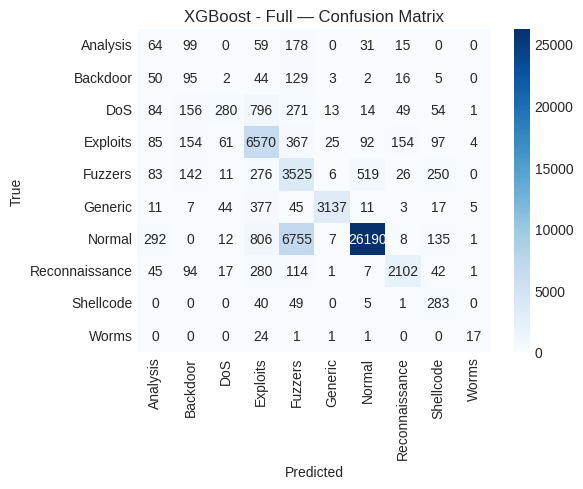

In [30]:
from sklearn.model_selection import GridSearchCV

print("Running XGBoost: Full Dataset...")
grid_full = GridSearchCV(xgb.XGBClassifier(random_state=42), xgb_params, cv=sCV, scoring='f1_weighted', n_jobs=-1)
grid_full.fit(X_train, y_train)

y_pred = grid_full.predict(X_test)
acc, f1, macro = evaluate("XGBoost - Full", y_test, y_pred)
XGB_RESULTS_Gridsearch["XGBoost - Full"] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': macro, 'K': X_train.shape[1]}


=== XGBoost (MI, K=30) ===
Accuracy : 0.7577   Weighted F1 : 0.7826, Macro F1: 0.5387
                precision    recall  f1-score   support

      Analysis       0.09      0.12      0.10       446
      Backdoor       0.13      0.27      0.17       346
           DoS       0.60      0.16      0.26      1718
      Exploits       0.71      0.86      0.78      7609
       Fuzzers       0.31      0.72      0.43      4838
       Generic       0.99      0.86      0.92      3657
        Normal       0.97      0.77      0.86     34206
Reconnaissance       0.88      0.78      0.83      2703
     Shellcode       0.31      0.74      0.44       378
         Worms       0.65      0.55      0.59        44

      accuracy                           0.76     55945
     macro avg       0.56      0.58      0.54     55945
  weighted avg       0.85      0.76      0.78     55945



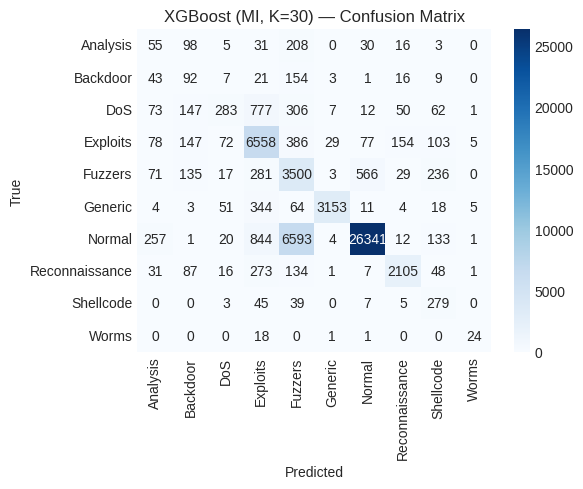

In [52]:

from sklearn.feature_selection import mutual_info_classif
mi_scores = mutual_info_classif(X_train, y_train, random_state=42)
top_k_idx = mi_scores.argsort()[::-1][:30]  # top 30

X_train_mi = X_train.iloc[:, top_k_idx]
X_test_mi  = X_test.iloc[:, top_k_idx]


grid_mi = GridSearchCV(
    xgb.XGBClassifier(random_state=42, eval_metric='mlogloss',
                       tree_method='hist', n_jobs=-1),
    xgb_params, cv=sCV, scoring='f1_weighted', n_jobs=-1
)
grid_mi.fit(X_train_mi, y_train)

y_pred = grid_mi.predict(X_test_mi)

label = "XGBoost (MI, K=30)"
acc, f1, macro = evaluate(label, y_test, y_pred)
XGB_RESULTS_Gridsearch[label] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': macro, 'K': 30}

Running XGBoost: SFS-Selected...

=== XGBoost (SFS) ===
Accuracy : 0.7382   Weighted F1 : 0.7630, Macro F1: 0.5200
                precision    recall  f1-score   support

      Analysis       0.08      0.06      0.07       446
      Backdoor       0.29      0.08      0.13       346
           DoS       0.52      0.10      0.16      1718
      Exploits       0.64      0.86      0.73      7609
       Fuzzers       0.28      0.73      0.40      4838
       Generic       0.99      0.84      0.91      3657
        Normal       0.98      0.75      0.85     34206
Reconnaissance       0.88      0.77      0.82      2703
     Shellcode       0.36      0.74      0.49       378
         Worms       0.58      0.70      0.64        44

      accuracy                           0.74     55945
     macro avg       0.56      0.56      0.52     55945
  weighted avg       0.84      0.74      0.76     55945



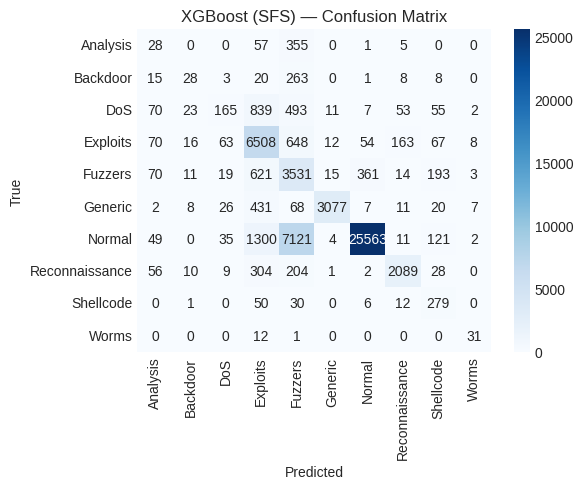

In [44]:
print("Running XGBoost: SFS-Selected...")

grid_sfs = GridSearchCV(
    xgb.XGBClassifier(random_state=42, eval_metric='mlogloss',
                       tree_method='hist', n_jobs=-1),
    xgb_params, cv=sCV, scoring='f1_weighted', n_jobs=-1
)
grid_sfs.fit(X_train[sfs_features], y_train)

y_pred = grid_sfs.predict(X_test[sfs_features])
label = "XGBoost (SFS)"
acc, f1, macro = evaluate(label, y_test, y_pred)
XGB_RESULTS_Gridsearch[label] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': macro, 'K': len(sfs_features)}

## Random Forest with GridSearchCV

In [45]:
from sklearn.ensemble import RandomForestClassifier

# Define common RF parameters
rf_params = {
    'n_estimators': [50, 100],
    'max_depth': [8, 10],
    'min_samples_split': [5],
}

sCV = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

Running Random Forest: Full Dataset...

=== RF - Full ===
Accuracy : 0.7197   Weighted F1 : 0.7411, Macro F1: 0.3833
                precision    recall  f1-score   support

      Analysis       0.00      0.00      0.00       446
      Backdoor       0.22      0.01      0.02       346
           DoS       0.86      0.03      0.06      1718
      Exploits       0.68      0.87      0.76      7609
       Fuzzers       0.27      0.86      0.41      4838
       Generic       1.00      0.81      0.90      3657
        Normal       0.98      0.72      0.83     34206
Reconnaissance       0.69      0.66      0.68      2703
     Shellcode       0.57      0.10      0.17       378
         Worms       0.00      0.00      0.00        44

      accuracy                           0.72     55945
     macro avg       0.53      0.41      0.38     55945
  weighted avg       0.84      0.72      0.74     55945



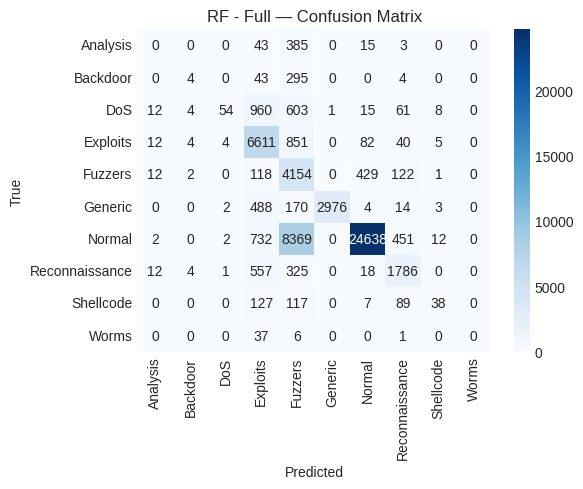

In [46]:
print("Running Random Forest: Full Dataset...")
grid_rf_full = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    rf_params, cv=sCV, scoring='f1_weighted', n_jobs=-1
)
grid_rf_full.fit(X_train, y_train)

y_pred = grid_rf_full.predict(X_test)
acc, f1, macro = evaluate("RF - Full", y_test, y_pred)
RF_RESULTS_Gridsearch["RF - Full"] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': macro, 'K': X_train.shape[1]}


=== RF (MI, K=30) ===
Accuracy : 0.7398   Weighted F1 : 0.7622, Macro F1: 0.4609
                precision    recall  f1-score   support

      Analysis       0.13      0.01      0.01       446
      Backdoor       0.13      0.08      0.10       346
           DoS       0.80      0.08      0.14      1718
      Exploits       0.67      0.87      0.76      7609
       Fuzzers       0.27      0.75      0.40      4838
       Generic       1.00      0.82      0.90      3657
        Normal       0.97      0.75      0.85     34206
Reconnaissance       0.83      0.76      0.80      2703
     Shellcode       0.38      0.55      0.45       378
         Worms       0.83      0.11      0.20        44

      accuracy                           0.74     55945
     macro avg       0.60      0.48      0.46     55945
  weighted avg       0.85      0.74      0.76     55945



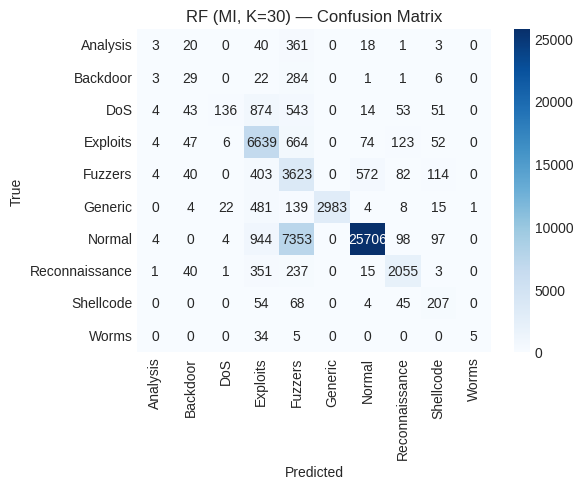

In [49]:
print("Running Random Forest: Filter-based (MI)...")
grid_rf_mi = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    rf_params, cv=sCV, scoring='f1_weighted', n_jobs=-1
)
grid_rf_mi.fit(X_train_mi, y_train)

best_k = 30
y_pred = grid_rf_mi.predict(X_test_mi)
label = f"RF (MI, K={best_k})"
acc, f1, macro = evaluate(label, y_test, y_pred)
RF_RESULTS_Gridsearch[label] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': macro, 'K': best_k}

Running Random Forest: SFS-Selected...

=== RF (SFS) ===
Accuracy : 0.7229   Weighted F1 : 0.7492, Macro F1: 0.4524
                precision    recall  f1-score   support

      Analysis       0.00      0.00      0.00       446
      Backdoor       0.27      0.06      0.10       346
           DoS       0.66      0.07      0.13      1718
      Exploits       0.62      0.86      0.72      7609
       Fuzzers       0.25      0.73      0.38      4838
       Generic       1.00      0.81      0.90      3657
        Normal       0.98      0.73      0.84     34206
Reconnaissance       0.92      0.75      0.83      2703
     Shellcode       0.47      0.57      0.51       378
         Worms       1.00      0.07      0.13        44

      accuracy                           0.72     55945
     macro avg       0.62      0.47      0.45     55945
  weighted avg       0.84      0.72      0.75     55945



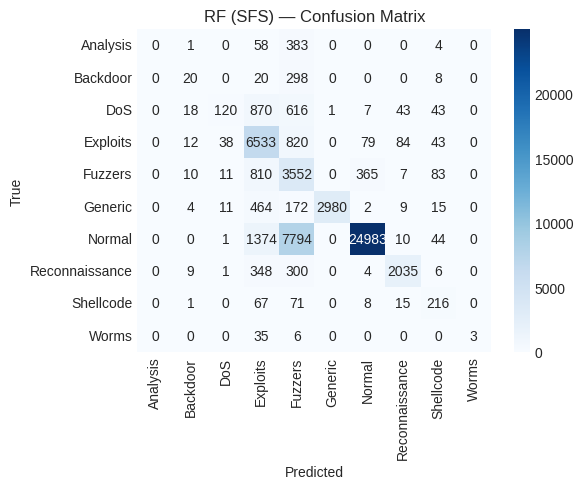

In [47]:
print("Running Random Forest: SFS-Selected...")
grid_rf_sfs = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    rf_params, cv=sCV, scoring='f1_weighted', n_jobs=-1
)

grid_rf_sfs.fit(X_train[sfs_features], y_train)

y_pred = grid_rf_sfs.predict(X_test[sfs_features])
label = "RF (SFS)"
acc, f1, macro = evaluate(label, y_test, y_pred)
RF_RESULTS_Gridsearch[label] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': macro, 'K': len(sfs_features)}

In [51]:
# Create a unified table of everything
final_summary = pd.DataFrame(RF_RESULTS_Gridsearch).T
print(final_summary.sort_values(by='Macro F1', ascending=False))

               Accuracy  Weighted F1  Macro F1      K
RF (MI, K=30)  0.739762     0.762163  0.460863   30.0
RF (SFS)       0.722889     0.749238  0.452358   15.0
RF - Full      0.719653     0.741135  0.383349  194.0


## SVM with GridSearchCV

Starting LinearSVC Hyperparameter Tuning...
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best C: 1

=== SVM - Baseline ===
Accuracy : 0.6197   Weighted F1 : 0.6562, Macro F1: 0.3342
                precision    recall  f1-score   support

      Analysis       0.16      0.53      0.25       446
      Backdoor       0.00      0.00      0.00       346
           DoS       0.55      0.02      0.03      1718
      Exploits       0.57      0.72      0.64      7609
       Fuzzers       0.22      0.80      0.35      4838
       Generic       0.96      0.81      0.88      3657
        Normal       0.97      0.61      0.75     34206
Reconnaissance       0.45      0.44      0.44      2703
     Shellcode       0.00      0.00      0.00       378
         Worms       0.00      0.00      0.00        44

      accuracy                           0.62     55945
     macro avg       0.39      0.39      0.33     55945
  weighted avg       0.79      0.62      0.66     55945



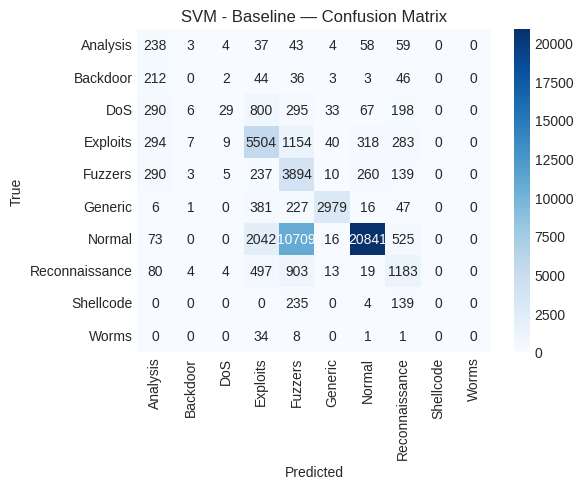


=== SVM (MI, K=30) ===
Accuracy : 0.6210   Weighted F1 : 0.6563, Macro F1: 0.3315
                precision    recall  f1-score   support

      Analysis       0.17      0.56      0.26       446
      Backdoor       0.00      0.00      0.00       346
           DoS       0.82      0.01      0.01      1718
      Exploits       0.55      0.74      0.63      7609
       Fuzzers       0.22      0.75      0.34      4838
       Generic       0.95      0.81      0.88      3657
        Normal       0.97      0.62      0.75     34206
Reconnaissance       0.46      0.43      0.45      2703
     Shellcode       0.00      0.00      0.00       378
         Worms       0.00      0.00      0.00        44

      accuracy                           0.62     55945
     macro avg       0.41      0.39      0.33     55945
  weighted avg       0.80      0.62      0.66     55945



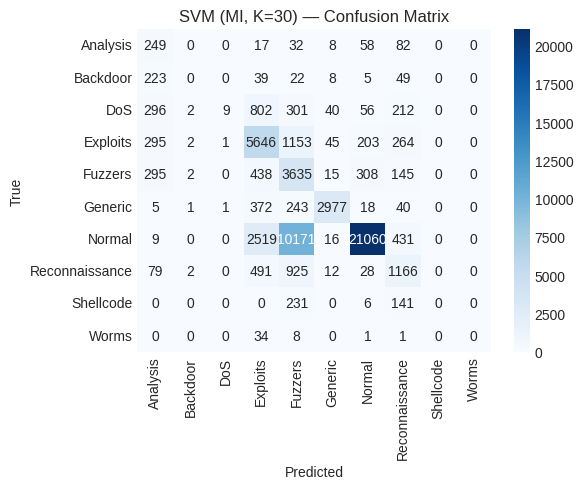


=== SVM (SFS, K=15) ===
Accuracy : 0.5743   Weighted F1 : 0.6096, Macro F1: 0.2705
                precision    recall  f1-score   support

      Analysis       0.00      0.00      0.00       446
      Backdoor       0.00      0.00      0.00       346
           DoS       0.33      0.00      0.00      1718
      Exploits       0.49      0.61      0.54      7609
       Fuzzers       0.20      0.82      0.32      4838
       Generic       0.97      0.82      0.89      3657
        Normal       0.93      0.59      0.72     34206
Reconnaissance       0.28      0.21      0.24      2703
     Shellcode       0.00      0.00      0.00       378
         Worms       0.00      0.00      0.00        44

      accuracy                           0.57     55945
     macro avg       0.32      0.30      0.27     55945
  weighted avg       0.74      0.57      0.61     55945



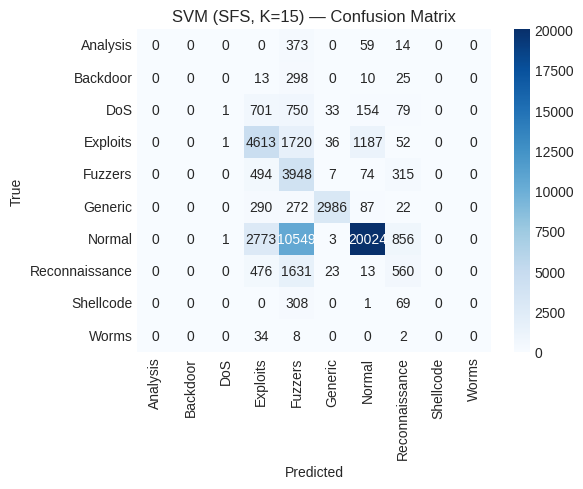


--- TUNED SVM SUMMARY ---
                 Accuracy  Weighted F1  Macro F1      K
SVM - Baseline   0.619680     0.656153  0.334223  194.0
SVM (MI, K=30)   0.621003     0.656297  0.331544   30.0
SVM (SFS, K=15)  0.574350     0.609586  0.270487   15.0


In [50]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC
import pandas as pd

# 1. Parameter grid for LinearSVC
svm_linear_params = {
    'C': [0.1, 1, 10]
}


print("Starting LinearSVC Hyperparameter Tuning...")
grid_search_svm = GridSearchCV(
    estimator=LinearSVC(max_iter=2000, random_state=42, dual='auto'),
    param_grid=svm_linear_params,
    cv=3,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)
grid_search_svm.fit(X_train[final_feature_list], y_train)
best_C = grid_search_svm.best_params_['C']
print(f"Best C: {best_C}")

# 3. Evaluate all subsets with best C
SVM_RESULTS_Gridsearch = {}
SVM_CONFIGS = [
    ("SVM - Baseline", X_train.columns.tolist()),
    ("SVM (MI, K=30)", final_feature_list),
    ("SVM (SFS, K=15)", sfs_features)
]

for label, f_list in SVM_CONFIGS:
    K_val = len(f_list)
    clf = LinearSVC(C=best_C, max_iter=2000, random_state=42, dual='auto')
    clf.fit(X_train[f_list], y_train)
    y_pred = clf.predict(X_test[f_list])
    acc, f1, macro = evaluate(label, y_test, y_pred)
    SVM_RESULTS_Gridsearch[label] = {'Accuracy': acc, 'Weighted F1': f1, 'Macro F1': macro, 'K': K_val}

# 4. Summary
svm_summary_df = pd.DataFrame(SVM_RESULTS_Gridsearch).T
print("\n--- TUNED SVM SUMMARY ---")
print(svm_summary_df.sort_values(by='Macro F1', ascending=False))

In [1]:
pip freeze | grep -i -E "^(numpy|pandas|scikit-learn|xgboost|matplotlib|seaborn|jupyterlab|ipykernel)=="

ipykernel==7.2.0
jupyterlab==4.5.6
matplotlib==3.10.8
numpy==2.4.3
pandas==3.0.1
scikit-learn==1.8.0
seaborn==0.13.2
xgboost==3.2.0
Note: you may need to restart the kernel to use updated packages.
